In [1]:
import sys

print(sys.executable)

c:\Users\kookie\OneDrive\MMA3001_project\.venv\Scripts\python.exe


# Week 3 — Reconstruction experiment development

This notebook continues from the cleaned and segmented Week 2 reference.

It develops and tests:

- simulated GPS downsampling;
- linear interpolation as the baseline;
- cubic spline as the approved alternative;
- PCHIP as a pilot candidate;
- supported-domain handling;
- method comparison;
- validation-population selection; and
- frozen acceptance criteria.

No interpolation is permitted across a trajectory segment boundary, and no method is permitted to extrapolate beyond retained GPS anchors.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml


current_folder = Path.cwd().resolve()

candidate_folders = [
    current_folder,
    current_folder.parent,
]

PROJECT_FOLDER = None

for candidate in candidate_folders:
    if (
        (candidate / "data").is_dir()
        and (candidate / "src").is_dir()
    ):
        PROJECT_FOLDER = candidate
        break

if PROJECT_FOLDER is None:
    raise FileNotFoundError(
        "Could not find the MMA3001 project folder."
    )


if str(PROJECT_FOLDER) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_FOLDER),
    )


from src.reconstruction import (
    build_support_audit,
    load_contract,
    load_reference,
    make_downsampling_mask,
    run_pilot,
    summarise_pilot,
    summarise_support,
)


CLEANED_FILE = (
    PROJECT_FOLDER
    / "data"
    / "processed"
    / "elephant_gps_cleaned_reference.csv"
)

PROCESSED_FOLDER = (
    PROJECT_FOLDER
    / "data"
    / "processed"
)

REPORTS_FOLDER = (
    PROJECT_FOLDER
    / "reports"
)

FIGURES_FOLDER = (
    PROJECT_FOLDER
    / "figures"
)

CONTRACT_FILE = (
    REPORTS_FOLDER
    / "experiment_contract.yaml"
)

PROCESSED_FOLDER.mkdir(
    parents=True,
    exist_ok=True,
)

REPORTS_FOLDER.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURES_FOLDER.mkdir(
    parents=True,
    exist_ok=True,
)

sns.set_theme(
    style="whitegrid"
)

pd.set_option(
    "display.max_columns",
    50,
)

print(
    "Project folder:",
    PROJECT_FOLDER,
)

print(
    "Cleaned input:",
    CLEANED_FILE,
)

print(
    "Experiment contract:",
    CONTRACT_FILE,
)

Project folder: C:\Users\kookie\OneDrive\MMA3001_project
Cleaned input: C:\Users\kookie\OneDrive\MMA3001_project\data\processed\elephant_gps_cleaned_reference.csv
Experiment contract: C:\Users\kookie\OneDrive\MMA3001_project\reports\experiment_contract.yaml


In [3]:
reference = load_reference(
    CLEANED_FILE
)

reference_checks = pd.Series(
    {
        "Rows": len(reference),
        "Animals": reference[
            "AnimalID"
        ].nunique(),
        "Segments": reference[
            "SegmentID"
        ].nunique(),
        "Duplicate animal-timestamps": int(
            reference.duplicated(
                [
                    "AnimalID",
                    "Timestamp",
                ]
            ).sum()
        ),
        "Missing required values": int(
            reference[
                [
                    "AnimalID",
                    "Timestamp",
                    "Latitude",
                    "Longitude",
                    "SegmentID",
                    "LocalX_m",
                    "LocalY_m",
                ]
            ].isna().sum().sum()
        ),
    },
    name="Observed value",
)

display(
    reference_checks.to_frame()
)


assert len(reference) == 59_994
assert reference["AnimalID"].nunique() == 6
assert reference["SegmentID"].nunique() == 77
assert not reference.duplicated(
    ["AnimalID", "Timestamp"]
).any()

print(
    "\nPASS: Week 2 cleaned reference is ready."
)

,Observed value
Rows,59994
Animals,6
Segments,77
Duplicate animal-timestamps,0
Missing required values,0



PASS: Week 2 cleaned reference is ready.


In [4]:
contract = load_contract(
    CONTRACT_FILE
)

print(
    yaml.safe_dump(
        contract,
        sort_keys=False,
    )
)

project:
  title: Elephant GPS sampling-accuracy optimisation
  engineering_use: 'Identify the longest tested GPS sampling interval that preserves
    acceptable movement-path reconstruction accuracy.

    '
  resource_claim: 'GPS fix reduction is used only as a proxy for reduced sensor activity,
    storage and transmission demand.

    '
  unsupported_claim: 'The project will not predict exact battery-life improvement
    because electrical power-consumption measurements are unavailable.

    '
input:
  cleaned_file: data/processed/elephant_gps_cleaned_reference.csv
  expected_rows: 59994
  expected_animals: 6
  expected_segments: 77
  coordinate_system_for_interpolation: local x and y coordinates in metres
  final_position_error_calculation: Haversine distance in metres
  numeric_precision: float64
sampling:
  reference_interval_minutes: 15
  simulated_intervals_minutes:
  - 30
  - 60
  - 120
  - 240
  offsets: every possible offset from 0 to k minus 1
  segment_gap_rule: start a ne

In [5]:
PILOT_ANIMAL = sorted(
    reference[
        "AnimalID"
    ].unique()
)[0]

segment_sizes = (
    reference.loc[
        reference[
            "AnimalID"
        ].eq(PILOT_ANIMAL)
    ]
    .groupby(
        "SegmentID"
    )
    .size()
    .sort_values(
        ascending=False
    )
)

PILOT_SEGMENTS = (
    segment_sizes
    .head(2)
    .index
    .tolist()
)

PILOT_INTERVALS = [
    60,
    120,
]

PILOT_METHODS = [
    "linear",
    "cubic",
    "pchip",
]

pilot_definition = pd.DataFrame(
    {
        "Setting": [
            "Pilot animal",
            "Pilot segment 1",
            "Pilot segment 2",
            "Pilot intervals",
            "Pilot methods",
        ],
        "Value": [
            PILOT_ANIMAL,
            PILOT_SEGMENTS[0],
            PILOT_SEGMENTS[1],
            str(PILOT_INTERVALS),
            str(PILOT_METHODS),
        ],
    }
)

display(
    pilot_definition
)

display(
    segment_sizes
    .head(10)
    .rename(
        "Fixes"
    )
    .to_frame()
)

,Setting,Value
0,Pilot animal,LOAF-18-f-2981-1
1,Pilot segment 1,LOAF-18-f-2981-1_S002
2,Pilot segment 2,LOAF-18-f-2981-1_S003
3,Pilot intervals,"[60, 120]"
4,Pilot methods,"['linear', 'cubic', 'pchip']"


,Fixes
SegmentID,
LOAF-18-f-2981-1_S002,2275
LOAF-18-f-2981-1_S003,1886
LOAF-18-f-2981-1_S011,1556
LOAF-18-f-2981-1_S007,1519
LOAF-18-f-2981-1_S004,733
LOAF-18-f-2981-1_S005,729
LOAF-18-f-2981-1_S010,430
LOAF-18-f-2981-1_S006,397
LOAF-18-f-2981-1_S009,191


In [6]:
pilot_predictions, pilot_cases = run_pilot(
    reference=reference,
    segment_ids=PILOT_SEGMENTS,
    intervals=PILOT_INTERVALS,
    methods=PILOT_METHODS,
)

pilot_summary = summarise_pilot(
    pilot_predictions,
    pilot_cases,
)


pilot_predictions.to_csv(
    PROCESSED_FOLDER
    / "week3_pilot_predictions.csv",
    index=False,
)

pilot_cases.to_csv(
    REPORTS_FOLDER
    / "week3_pilot_cases.csv",
    index=False,
)

pilot_summary.to_csv(
    REPORTS_FOLDER
    / "week3_pilot_method_summary.csv",
    index=False,
)


print(
    "Pilot prediction rows:",
    len(pilot_predictions),
)

print(
    "Pilot cases:",
    len(pilot_cases),
)

display(
    pilot_summary.round(3)
)

Pilot prediction rows: 124422
Pilot cases: 72


,Method,Interval_min,PredictedFixes,MedianPositionError_m,MAE_m,RMSE_m,P95PositionError_m,MaximumPositionError_m,OvershootCount,OvershootPercent,SuccessfulCases,MedianAbsolutePathError_percent,P95AbsolutePathError_percent,MaximumReconstructedSpeed_mps,TotalInterpolationRuntime_s,TotalCases,FailedCases
0,cubic,60,12459,51.390,71.995,110.798,188.387,1883.076,4270,34.272,8,12.620,15.253,0.914,0.012,8,0
1,cubic,120,29015,88.149,122.531,170.906,344.466,1973.320,10634,36.650,16,18.583,22.524,0.624,0.011,16,0
2,linear,60,12459,50.604,72.936,111.923,201.426,1796.338,0,0.000,8,16.354,19.372,0.831,0.002,8,0
3,linear,120,29015,89.208,126.277,177.214,364.250,1902.104,0,0.000,16,23.448,27.090,0.576,0.002,16,0
4,pchip,60,12459,47.174,68.925,108.737,190.451,1794.897,0,0.000,8,15.817,18.785,0.994,0.007,8,0
5,pchip,120,29015,80.948,118.188,169.764,347.627,1941.143,0,0.000,16,22.835,26.387,0.684,0.012,16,0


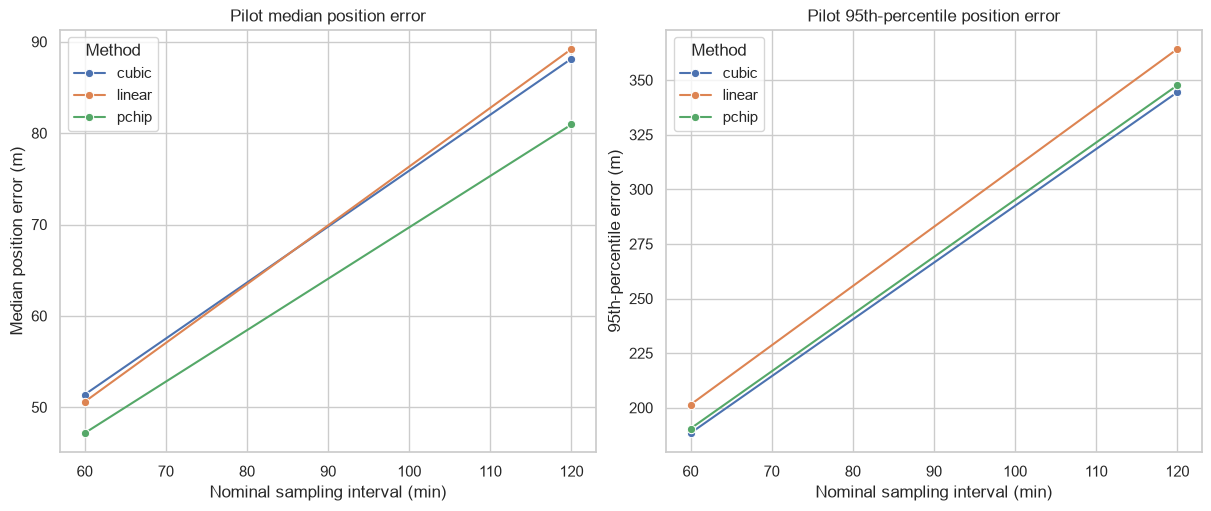

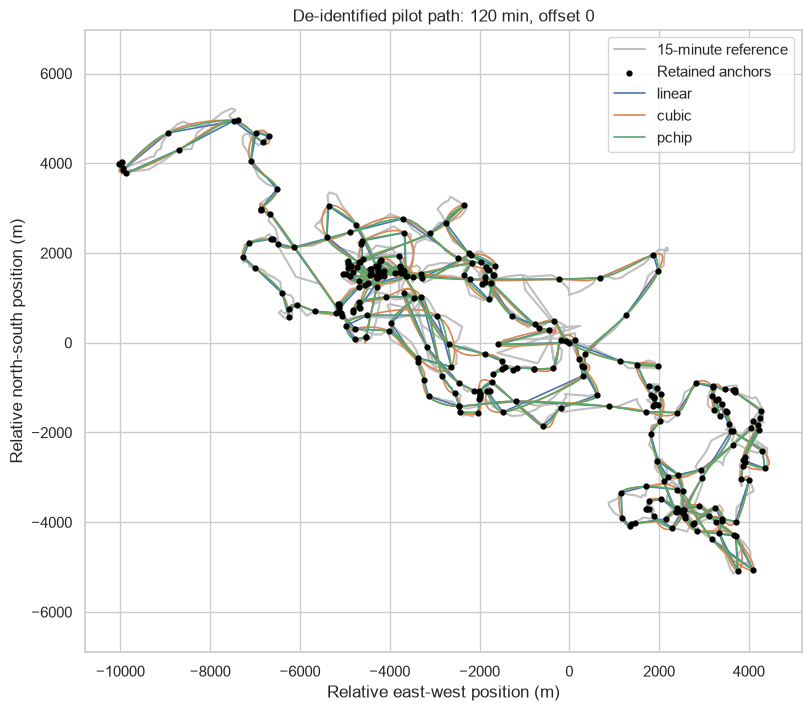

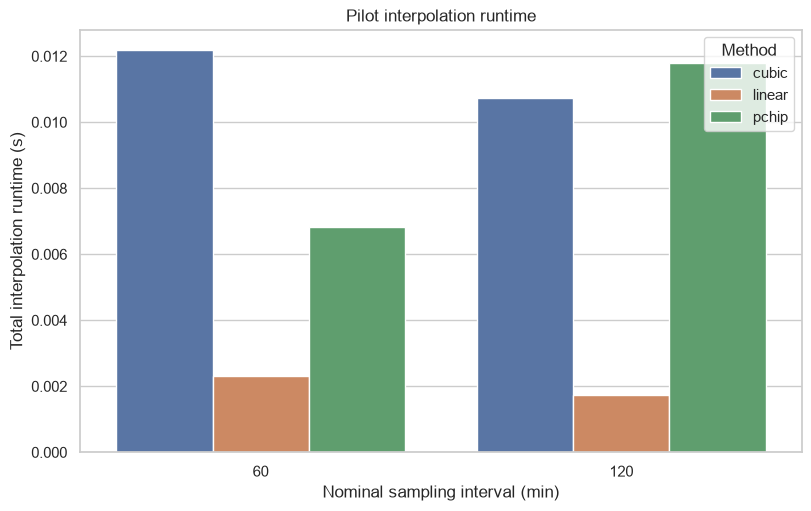

Saved: week3_01_pilot_error_comparison.png
Saved: week3_02_pilot_path_example.png
Saved: week3_03_pilot_runtime.png


In [7]:
# Figure 1: typical and tail position errors

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
    constrained_layout=True,
)

sns.lineplot(
    data=pilot_summary,
    x="Interval_min",
    y="MedianPositionError_m",
    hue="Method",
    marker="o",
    ax=axes[0],
)

axes[0].set(
    title="Pilot median position error",
    xlabel="Nominal sampling interval (min)",
    ylabel="Median position error (m)",
)

sns.lineplot(
    data=pilot_summary,
    x="Interval_min",
    y="P95PositionError_m",
    hue="Method",
    marker="o",
    ax=axes[1],
)

axes[1].set(
    title="Pilot 95th-percentile position error",
    xlabel="Nominal sampling interval (min)",
    ylabel="95th-percentile error (m)",
)

figure_1_path = (
    FIGURES_FOLDER
    / "week3_01_pilot_error_comparison.png"
)

fig.savefig(
    figure_1_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# Figure 2: declared de-identified path example

example_segment_id = PILOT_SEGMENTS[0]
example_interval = 120
example_offset = 0

example_segment = (
    reference.loc[
        reference[
            "SegmentID"
        ].eq(example_segment_id)
    ]
    .sort_values(
        "Timestamp"
    )
    .copy()
)

example_mask = make_downsampling_mask(
    example_segment,
    example_interval,
    example_offset,
)

example_anchors = example_segment.loc[
    example_mask[
        "Retained"
    ].to_numpy()
].copy()

x_origin = float(
    example_segment[
        "LocalX_m"
    ].iloc[0]
)

y_origin = float(
    example_segment[
        "LocalY_m"
    ].iloc[0]
)

fig, ax = plt.subplots(
    figsize=(8, 7),
    constrained_layout=True,
)

ax.plot(
    example_segment["LocalX_m"] - x_origin,
    example_segment["LocalY_m"] - y_origin,
    color="0.75",
    linewidth=1.5,
    label="15-minute reference",
)

ax.scatter(
    example_anchors["LocalX_m"] - x_origin,
    example_anchors["LocalY_m"] - y_origin,
    s=12,
    color="black",
    label="Retained anchors",
    zorder=5,
)

for method in PILOT_METHODS:
    method_predictions = (
        pilot_predictions.loc[
            pilot_predictions[
                "SegmentID"
            ].eq(example_segment_id)
            & pilot_predictions[
                "Interval_min"
            ].eq(example_interval)
            & pilot_predictions[
                "Offset"
            ].eq(example_offset)
            & pilot_predictions[
                "Method"
            ].eq(method)
        ]
        .sort_values(
            "Timestamp"
        )
    )

    anchor_positions = (
        example_anchors[
            [
                "Timestamp",
                "LocalX_m",
                "LocalY_m",
            ]
        ]
        .rename(
            columns={
                "LocalX_m": "PlotX_m",
                "LocalY_m": "PlotY_m",
            }
        )
    )

    estimated_positions = (
        method_predictions[
            [
                "Timestamp",
                "EstimatedX_m",
                "EstimatedY_m",
            ]
        ]
        .rename(
            columns={
                "EstimatedX_m": "PlotX_m",
                "EstimatedY_m": "PlotY_m",
            }
        )
    )

    combined_positions = (
        pd.concat(
            [
                anchor_positions,
                estimated_positions,
            ],
            ignore_index=True,
        )
        .sort_values(
            "Timestamp"
        )
    )

    ax.plot(
        combined_positions["PlotX_m"] - x_origin,
        combined_positions["PlotY_m"] - y_origin,
        linewidth=1.2,
        label=method,
    )

ax.set(
    title=(
        "De-identified pilot path: "
        f"{example_interval} min, "
        f"offset {example_offset}"
    ),
    xlabel="Relative east-west position (m)",
    ylabel="Relative north-south position (m)",
)

ax.axis("equal")
ax.legend()

figure_2_path = (
    FIGURES_FOLDER
    / "week3_02_pilot_path_example.png"
)

fig.savefig(
    figure_2_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# Figure 3: runtime comparison

fig, ax = plt.subplots(
    figsize=(8, 5),
    constrained_layout=True,
)

sns.barplot(
    data=pilot_summary,
    x="Interval_min",
    y="TotalInterpolationRuntime_s",
    hue="Method",
    ax=ax,
)

ax.set(
    title="Pilot interpolation runtime",
    xlabel="Nominal sampling interval (min)",
    ylabel="Total interpolation runtime (s)",
)

figure_3_path = (
    FIGURES_FOLDER
    / "week3_03_pilot_runtime.png"
)

fig.savefig(
    figure_3_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved:",
    figure_1_path.name,
)

print(
    "Saved:",
    figure_2_path.name,
)

print(
    "Saved:",
    figure_3_path.name,
)

In [8]:
D4_COLUMNS = [
    "Method",
    "Interval_min",
    "PredictedFixes",
    "MedianPositionError_m",
    "RMSE_m",
    "P95PositionError_m",
    "MedianAbsolutePathError_percent",
    "OvershootPercent",
    "MaximumReconstructedSpeed_mps",
    "TotalInterpolationRuntime_s",
    "FailedCases",
]

d4_evidence = (
    pilot_summary[
        D4_COLUMNS
    ]
    .sort_values(
        [
            "Interval_min",
            "Method",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    d4_evidence.round(3)
)

,Method,Interval_min,PredictedFixes,MedianPositionError_m,RMSE_m,P95PositionError_m,MedianAbsolutePathError_percent,OvershootPercent,MaximumReconstructedSpeed_mps,TotalInterpolationRuntime_s,FailedCases
0,cubic,60,12459,51.390,110.798,188.387,12.620,34.272,0.914,0.012,0
1,linear,60,12459,50.604,111.923,201.426,16.354,0.000,0.831,0.002,0
2,pchip,60,12459,47.174,108.737,190.451,15.817,0.000,0.994,0.007,0
3,cubic,120,29015,88.149,170.906,344.466,18.583,36.650,0.624,0.011,0
4,linear,120,29015,89.208,177.214,364.250,23.448,0.000,0.576,0.002,0
5,pchip,120,29015,80.948,169.764,347.627,22.835,0.000,0.684,0.012,0
